In [2]:
import sys

sys.path.append("..")  # zodat de map src gevonden wordt

from src.preprocessing import NUMERIC_COLS, StrokeData

data = StrokeData()
X, y = data.get_xy()       # features en target van de trainset
X_test = data.get_test()

## 5. Evaluatie

In dit hoofdstuk bepalen we met welke metrics we kunnen meten hoe goed een model presteert. We laten de uitkomsten zien met een eenvoudig model en leggen uit hoe iedere metric wordt berekend.

### 5.1 Train- en validatieset
De testset van Kaggle bevat geen `stroke`-kolom, dus daarmee kunnen we zelf niet controleren hoe goed een model is. Daarom splitsen we de opgeschoonde trainset in een trainset (80%) om het model op te trainen en een validatieset (20%) om het te testen op patiënten die het model nog niet heeft gezien.

We gebruiken `stratify=y`, zodat beide sets hetzelfde percentage stroke-patiënten (1,54%) bevatten. Zonder stratificatie zouden er door toeval te weinig stroke-patiënten in de validatieset kunnen komen.

In [4]:
from sklearn.model_selection import train_test_split

# 80% train, 20% validatie; stratify zorgt voor 1,54% stroke in beide sets
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Train:", X_train.shape, "| stroke-patiënten:", y_train.sum())
print("Validatie:", X_val.shape, "| stroke-patiënten:", y_val.sum())

Train: (26835, 15) | stroke-patiënten: 414
Validatie: (6709, 15) | stroke-patiënten: 103


**Observatie:** de trainset bevat 26.835 patiënten (414 met stroke) en de validatieset 6.709 patiënten (103 met stroke). In beide sets is het aandeel stroke-patiënten 1,54%, gelijk aan de volledige dataset.


### 5.2 Metrics voor binaire classificatie
Bij binaire classificatie (stroke ja/nee) kunnen we met de volgende metrics bepalen hoe goed een model presteert:
- **Accuracy**
- **Precision**
- **Recall**
- **F1-score**

In 5.4 leggen we met een confusion matrix uit hoe iedere metric wordt berekend.

### 5.3 Gekozen model en uitkomsten
Om de metrics te demonstreren, gebruiken we **logistic regression**: een eenvoudig model voor binaire classificatie. We trainen het model bewust zonder technieken voor imbalanced data, zodat we zien hoe de metrics zich gedragen bij een standaardmodel.

We gebruiken een pipeline: eerst worden de features gestandaardiseerd zie 4.8, daarna wordt het model getraind. De StandardScaler wordt zo alleen op de trainset gefit, waardoor er geen informatie uit de validatieset lekt (data leakage).

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import pandas as pd

# Pipeline: eerst standaardiseren, dan logistic regression
model = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=1000, random_state=42)),
])

# Train het model en voorspel de validatieset
model.fit(X_train, y_train)
y_pred = model.predict(X_val)

# Bereken de vier metrics 
scores = pd.Series({
    "accuracy": accuracy_score(y_val, y_pred),
    "precision": precision_score(y_val, y_pred, zero_division=0),
    "recall": recall_score(y_val, y_pred),
    "f1": f1_score(y_val, y_pred),
}).round(3)

print("Aantal voorspellingen per klasse:",
      pd.Series(y_pred).value_counts().to_dict())
scores

Aantal voorspellingen per klasse: {0: 6709}


accuracy     0.985
precision    0.000
recall       0.000
f1           0.000
dtype: float64

**Observaties:**
- Het model voorspelt voor alle 6.709 patiënten "geen stroke". Doordat maar 1,54% van de patiënten een herseninfarct heeft, leert het model dat "altijd 0 zeggen" bijna altijd goed is.
- De accuracy is 0,985 (98,5%): dat lijkt uitstekend.
- Maar precision, recall en F1 zijn 0: het model vindt geen enkele van de 103 patiënten met een herseninfarct.
- Accuracy geeft hier dus een misleidend beeld. In 5.4 laten we met de confusion matrix zien hoe dit komt.

### 5.4 Confusion matrix en berekening van de metrics
Een **confusion matrix** zet de echte waarden tegenover de voorspellingen van het model. Zo zien we niet alleen hoeveel voorspellingen goed zijn, maar ook welke soort fouten het model maakt:

| | **Voorspeld: geen stroke (0)** | **Voorspeld: stroke (1)** |
|---|---|---|
| **Echt: geen stroke (0)** | **TN** – True Negative | **FP** – False Positive |
| **Echt: stroke (1)** | **FN** – False Negative | **TP** – True Positive |



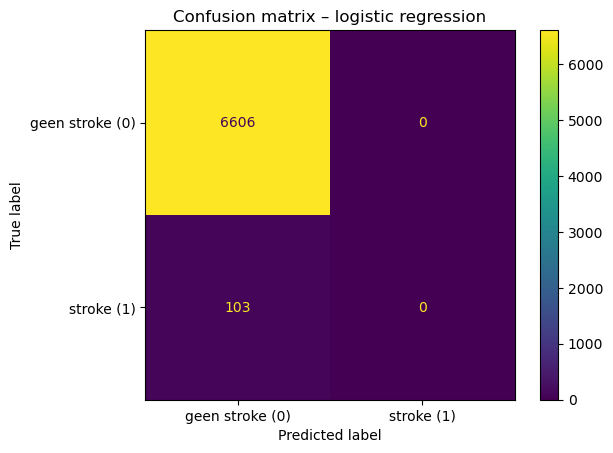

TN: 6606 | FP: 0 | FN: 103 | TP: 0


In [13]:
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             confusion_matrix, f1_score, precision_score,
                             recall_score)
import matplotlib.pyplot as plt

# Confusion matrix als grafiek
ConfusionMatrixDisplay.from_predictions(
    y_val, y_pred, display_labels=["geen stroke (0)", "stroke (1)"]
)
plt.title("Confusion matrix – logistic regression")
plt.show()

# De vier vakjes los uitlezen: ravel() zet de 2x2-tabel op één rij
tn, fp, fn, tp = confusion_matrix(y_val, y_pred).ravel()
print("TN:", tn, "| FP:", fp, "| FN:", fn, "| TP:", tp)

**Observaties:**
- **TN = 6.606:** alle patiënten zonder herseninfarct worden correct als "geen stroke" voorspeld.
- **FP = 0:** het model geeft nooit vals alarm, maar dat komt doordat het nooit "stroke" voorspelt.
- **FN = 103:** **alle** 103 patiënten met een herseninfarct worden gemist. 
- **TP = 0:** het model vindt geen enkele patiënt met een herseninfarct.

#### Berekening van de metrics
Met de getallen uit de confusion matrix (TN = 6.606, FP = 0, FN = 103, TP = 0) berekenen we iedere metric:

**Accuracy**: welk deel van alle voorspellingen is goed?
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN} = \frac{0 + 6606}{6709} = 0{,}985$$

**Precision**: van alle patiënten die het model als "stroke" aanwijst, hoeveel hebben echt een herseninfarct gehad?
$$\text{Precision} = \frac{TP}{TP + FP} = \frac{0}{0 + 0}$$
Delen door 0 kan niet, omdat het model nooit "stroke" voorspelt. Scikit-learn geeft dan 0.

**Recall**: van alle patiënten die echt een herseninfarct hebben gehad, hoeveel vindt het model?
$$\text{Recall} = \frac{TP}{TP + FN} = \frac{0}{0 + 103} = 0$$

**F1-score**: combineert precision en recall in één getal.
$$F1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}} = 2 \cdot \frac{0 \cdot 0}{0 + 0} = 0$$

**Conclusie:** de handmatige berekeningen geven dezelfde uitkomsten als scikit-learn in 5.3. De accuracy is hoog (98,5%) doordat bijna alle patiënten in de grootste klasse (geen stroke) zitten. Precision, recall en F1 kijken juist naar de stroke-patiënten en laten zien dat het model hier niets waard is.

#### Vergelijking: een model dat altijd "stroke" voorspelt
Onze logistic regression voorspelt bij niemand "stroke". Om te zien hoe de metrics reageren op het tegenovergestelde, berekenen we ze ook voor een "dom" model dat bij iedere patiënt "stroke" voorspelt. Dit model gebruikt geen enkele feature; het is alleen bedoeld als vergelijking.

In [16]:
# Een "dom" model dat bij iedereen stroke (1) voorspelt
y_pred_alles_1 = [1] * len(y_val)

print("Accuracy: ", round(accuracy_score(y_val, y_pred_alles_1), 3))
print("Precision:", round(precision_score(y_val, y_pred_alles_1), 3))
print("Recall:   ", round(recall_score(y_val, y_pred_alles_1), 3))
print("F1:       ", round(f1_score(y_val, y_pred_alles_1), 3))

Accuracy:  0.015
Precision: 0.015
Recall:    1.0
F1:        0.03


Samen met de logistic regression hebben we nu twee waardeloze modellen:

| Model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Logistic regression (altijd "geen stroke") | 0,985 | 0 | 0 | **0** |
| Altijd "stroke" | 0,015 | 0,015 | 1,0 | **0,03** |

### 5.5 Waarom de F1-score?
Kaggle beoordeelt de modellen met de F1-score. De twee modellen hierboven laten zien waarom dit voor dit vraagstuk de beste maatstaf is:

**1. Accuracy is misleidend bij imbalanced data.**
De logistic regression haalt 98,5% accuracy, terwijl het geen enkele stroke-patiënt vindt. Dat komt doordat accuracy ook de 6.606 True Negatives meetelt: de grote groep gezonde patiënten. Omdat maar 1,54% een herseninfarct heeft, scoort "altijd nee zeggen" al bijna perfect.

**2. Recall alleen is ook niet genoeg.**
Het model dat altijd "stroke" voorspelt, heeft een perfecte recall (1,0), maar 6.606 van de 6.709 meldingen zijn vals alarm. Voor artsen is zo'n model net zo onbruikbaar.

**3. De F1-score combineert precision en recall.**
De F1-score wordt laag zodra precision **of** recall laag is. Een model scoort dus alleen hoog als het zowel veel stroke-patiënten vindt (weinig FN) als weinig vals alarm geeft (weinig FP). Beide waardeloze modellen hierboven krijgen daarom terecht een F1-score van (bijna) 0.

**4. De F1-score kijkt naar de stroke-patiënten.**
De F1-score gebruikt alleen TP, FP en FN, en geen TN. De grote groep gezonde patiënten kan de score dus niet kunstmatig hoog maken, zoals bij accuracy gebeurt.

**Kanttekening:** in deze medische toepassing is een gemiste patiënt (FN) erger dan een vals alarm (FP). De F1-score weegt precision en recall even zwaar.

### 5.6 Conclusie
Voor binaire classificatie kunnen we een model beoordelen met accuracy, precision, recall en de F1-score. Omdat slechts 1,54% van de patiënten een herseninfarct heeft, is accuracy misleidend: een model dat nooit "stroke" voorspelt, haalt al 98,5%. De **F1-score** is voor dit vraagstuk de beste maatstaf, omdat hij alleen hoog is als het model zowel veel stroke-patiënten vindt als weinig vals alarm geeft. In hoofdstuk 6 gebruiken we daarom de F1-score om de modellen te vergelijken en af te stellen, en houden we daarnaast de recall in de gaten.